In [19]:
import pandas as pd
import numpy as np
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt

base_path = Path('cirrhosis.csv')

# Analiza i przetwarzanie danych pacjentów z marskością wątroby

#### Ten notebook ma na celu przeanalizowanie i przetworzenie zbioru danych pacjentów z marskością wątroby w taki sposób, by mógł on być użyty do nauki modelu klasyfikacji przeżywalności pacjenta (Status: D = zgon, C = cenzurowanie, CL = transplantacja wątroby).

Tabela z wyjaśnieniem poszczególnych kolumn:

| Kolumna           | Opis                                                                                          |
| ----------------- | --------------------------------------------------------------------------------------------- |
| **ID**            | Identyfikator pacjenta.                                                                       |
| **N_Days**        | Liczba dni obserwacji od rejestracji do śmierci, transplantacji watroby lub czasu badania w lipcu 1986r.                          |
| **Status**        | Status pacjenta (D = zgon, C = cenzurowanie, CL = transplantacja wątroby).                   |
| **Drug**          | Podawany lek (D-penicillamine lub Placebo).            |
| **Age**           | Wiek pacjenta w dniach.                                                                       |
| **Sex**           | Płeć pacjenta (F = kobieta, M = mężczyzna).                                                  |
| **Ascites**       | Obecność wodobrzusza (Y = tak, N = nie).                                                      |
| **Hepatomegaly**  | Powiększenie wątroby (Y = tak, N = nie).                                                      |
| **Spiders**       | Naczyniak pajączkowaty (Y = tak, N = nie).                                                    |
| **Edema**         | Obrzęk (N = brak, S = obrzęk bez terapii diuretycznej, Y = obrzęk mimo terapii).             |
| **Bilirubin**     | Stężenie bilirubiny w surowicy [mg/dl].                                                       |
| **Cholesterol**   | Stężenie cholesterolu w surowicy [mg/dl].                                                     |
| **Albumin**       | Stężenie albuminy w surowicy [mg/dl].                                                         |
| **Copper**        | Stężenie miedzi w moczu [ug/day].                                                             |
| **Alk_Phos**      | Aktywność fosfatazy alkalicznej [U/liter].                                                    |
| **SGOT**          | Aktywność aminotransferazy asparaginianowej [U/ml].                                           |
| **Tryglicerides** | Stężenie trójglicerydów w surowicy [mg/dl].                                                   |
| **Platelets**     | Liczba płytek krwi [ml/1000].                                                                 |
| **Prothrombin**   | Czas protrombinowy [s].                                                                       |
| **Stage**         | Stadium histologiczne marskości (1–4).                                                        |

## ***Podstawowa analiza i statystyka danych***

### Wczytanie danych

In [20]:
cirrhosis_data = pd.read_csv(base_path)

### Rozmiar danych

In [21]:
cirrhosis_data.shape

(418, 20)

Zbiór zawiera 418 rekordów zawierających dane pacjentów oraz 20 kolumn.

### Podgląd na parę pierwszych wartości

In [22]:
cirrhosis_data.head()

,ID,N_Days,Status,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage
0,1,400,D,D-penicillamine,21464,F,Y,Y,Y,Y,14.5,261.0,2.60,156.0,1718.0,137.95,172.0,190.0,12.2,4.0
1,2,4500,C,D-penicillamine,20617,F,N,Y,Y,N,1.1,302.0,4.14,54.0,7394.8,113.52,88.0,221.0,10.6,3.0
2,3,1012,D,D-penicillamine,25594,M,N,N,N,S,1.4,176.0,3.48,210.0,516.0,96.10,55.0,151.0,12.0,4.0
3,4,1925,D,D-penicillamine,19994,F,N,Y,Y,S,1.8,244.0,2.54,64.0,6121.8,60.63,92.0,183.0,10.3,4.0
4,5,1504,CL,Placebo,13918,F,N,Y,Y,N,3.4,279.0,3.53,143.0,671.0,113.15,72.0,136.0,10.9,3.0


### Opis danych

In [23]:
cirrhosis_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ID             418 non-null    int64  
 1   N_Days         418 non-null    int64  
 2   Status         418 non-null    str    
 3   Drug           312 non-null    str    
 4   Age            418 non-null    int64  
 5   Sex            418 non-null    str    
 6   Ascites        312 non-null    str    
 7   Hepatomegaly   312 non-null    str    
 8   Spiders        312 non-null    str    
 9   Edema          418 non-null    str    
 10  Bilirubin      418 non-null    float64
 11  Cholesterol    284 non-null    float64
 12  Albumin        418 non-null    float64
 13  Copper         310 non-null    float64
 14  Alk_Phos       312 non-null    float64
 15  SGOT           312 non-null    float64
 16  Tryglicerides  282 non-null    float64
 17  Platelets      407 non-null    float64
 18  Prothrombin    416 no

Mamy 12 kolumn numerycznych oraz 7 kolumn kategorialnych.  
Widzimy, że w kolumnach Drug, Ascites, Hepatomegaly, Spiders, Cholesterol, Copper, Alk_Phos, SGOT, Tryglicerides wystepuję znacząca ilość wartości null. W kolumnach Platelets, Prothombin oraz Stage występuje niewielka ilość wartości null.

### Sprawdzenie procentu brakujących wartości per kolumna

In [25]:
def get_percentage_missing(df, axis):
    missing = df.isna().sum(axis=axis)
    missing_perc = np.round(missing / df.shape[axis] * 100, 2)
    return missing_perc[missing_perc > 0]

missing_cols = get_percentage_missing(cirrhosis_data, axis=0)
print("Kolumny z brakującymi wartościami [%]:")
missing_cols

Kolumny z brakującymi wartościami [%]:


Drug             25.36
Ascites          25.36
Hepatomegaly     25.36
Spiders          25.36
Cholesterol      32.06
Copper           25.84
Alk_Phos         25.36
SGOT             25.36
Tryglicerides    32.54
Platelets         2.63
Prothrombin       0.48
Stage             1.44
dtype: float64

Jak widać sporo kolumn ma ponad 25% brakujących wartości, może tą wpłynąć na skuteczność uczenia modelu, ponieważ będzię on miał zbyt mało informacji/ zbyt mało wartości, żeby poprawnie nauczyć się klasyfikować. W miarę możlwiości w kolejnej sekcji tego notebooka zostanie przeprowadzone uzupełnienie danych null.

### Usunięcie kolumny ID, która nie ma żadnej wartości analitycznej

In [26]:
cirrhosis_data = cirrhosis_data.drop(columns=['ID'])
cirrhosis_data.head(1)

,N_Days,Status,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage
0,400,D,D-penicillamine,21464,F,Y,Y,Y,Y,14.5,261.0,2.6,156.0,1718.0,137.95,172.0,190.0,12.2,4.0


### Podstawowe statystyki dla kolumn numerycznych

In [27]:
cirrhosis_data.describe()

,N_Days,Age,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage
count,418.000000,418.000000,418.000000,284.000000,418.000000,310.000000,312.000000,312.000000,282.000000,407.000000,416.000000,412.000000
mean,1917.782297,18533.351675,3.220813,369.510563,3.497440,97.648387,1982.655769,122.556346,124.702128,257.024570,10.731731,3.024272
std,1104.672992,3815.845055,4.407506,231.944545,0.424972,85.613920,2140.388824,56.699525,65.148639,98.325585,1.022000,0.882042
min,41.000000,9598.000000,0.300000,120.000000,1.960000,4.000000,289.000000,26.350000,33.000000,62.000000,9.000000,1.000000
25%,1092.750000,15644.500000,0.800000,249.500000,3.242500,41.250000,871.500000,80.600000,84.250000,188.500000,10.000000,2.000000
50%,1730.000000,18628.000000,1.400000,309.500000,3.530000,73.000000,1259.000000,114.700000,108.000000,251.000000,10.600000,3.000000
75%,2613.500000,21272.500000,3.400000,400.000000,3.770000,123.000000,1980.000000,151.900000,151.000000,318.000000,11.100000,4.000000
max,4795.000000,28650.000000,28.000000,1775.000000,4.640000,588.000000,13862.400000,457.250000,598.000000,721.000000,18.000000,4.000000


### Sprawdzenie czy jakiś wiersz zawiera znaczącą liczbę wartości NaN

In [31]:
missing_rows_sorted = get_percentage_missing(cirrhosis_data, axis=1).sort_values(ascending=False)
print("Wiersze z brakującymi wartościami posortowane malejąco [%]:")
print(missing_rows_sorted)
print()
rows_to_drop = missing_rows_sorted[missing_rows_sorted >= 50].index
print("Numery wierszy do usunięcia (>= 50% brakujących wartości):", rows_to_drop.tolist())

Wiersze z brakującymi wartościami posortowane malejąco [%]:
358    52.63
333    52.63
332    52.63
336    52.63
346    52.63
       ...  
125     5.26
237     5.26
260     5.26
128     5.26
167     5.26
Length: 142, dtype: float64

Numery wierszy do usunięcia (>= 50% brakujących wartości): [358, 333, 332, 336, 346, 342, 324, 326, 327, 312, 318, 321, 316, 315, 367]


Mamy  15 wierszy, które zawierają mniej niż 50 % danych o pacjencie.
Jako iż jest to znaczący procent, te wiersze zostaną usunięte. 

In [32]:
cirrhosis_data = cirrhosis_data.drop(index=rows_to_drop)
print("Rozmiar po usunięciu wierszy:", cirrhosis_data.shape)

Rozmiar po usunięciu wierszy: (403, 19)


Po tym działaniu liczba wartości NULL w poszczególnych kolumnach prezętuję się następująco:

In [33]:
cirrhosis_data.info()

<class 'pandas.DataFrame'>
Index: 403 entries, 0 to 417
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   N_Days         403 non-null    int64  
 1   Status         403 non-null    str    
 2   Drug           312 non-null    str    
 3   Age            403 non-null    int64  
 4   Sex            403 non-null    str    
 5   Ascites        312 non-null    str    
 6   Hepatomegaly   312 non-null    str    
 7   Spiders        312 non-null    str    
 8   Edema          403 non-null    str    
 9   Bilirubin      403 non-null    float64
 10  Cholesterol    284 non-null    float64
 11  Albumin        403 non-null    float64
 12  Copper         310 non-null    float64
 13  Alk_Phos       312 non-null    float64
 14  SGOT           312 non-null    float64
 15  Tryglicerides  282 non-null    float64
 16  Platelets      399 non-null    float64
 17  Prothrombin    403 non-null    float64
 18  Stage          403 non-nul

# **Pozbycie się brakujących wartości**

Brakujące wartości:
- **Drug** (brakuje 91) – kolumna kategorialna
- **Ascites** (brakuje 91) – kolumna kategorialna
- **Hepatomegaly** (brakuje 91) – kolumna kategorialna
- **Spiders** (brakuje 91) – kolumna kategorialna
- **Cholesterol** (brakuje 119) – kolumna numeryczna
- **Copper** (brakuje 93) – kolumna numeryczna
- **Alk_Phos** (brakuje 91) – kolumna numeryczna
- **SGOT** (brakuje 91) – kolumna numeryczna
- **Tryglicerides** (brakuje 121) – kolumna numeryczna
- **Platelets** (brakuje 4) – kolumna numeryczna

## Kolumny numeryczne

Definiuję funkcję pomocniczą do rysowania histogramu z zaznaczoną średnią i medianą aby podjąć decyzję czym uzupełniać brakujące dane.

In [34]:
def plot_numeric_histogram(df, column_name):
    data = df[column_name].dropna()
    mean_val = data.mean()
    median_val = data.median()

    plt.figure(figsize=(6, 4))
    plt.hist(data, bins=30, color='steelblue', edgecolor='black')
    plt.axvline(mean_val, color='red', linestyle='--', linewidth=2, label=f'Mean: {mean_val:.2f}')
    plt.axvline(median_val, color='green', linestyle='-', linewidth=2, label=f'Median: {median_val:.2f}')

    plt.title(f'Distribution of {column_name}')
    plt.xlabel(column_name)
    plt.ylabel('Frequency')
    plt.legend()
    plt.tight_layout()
    plt.show()

### Cholesterol

Dla zmiennej Cholesterol najpierw zbadam jej rozkład, aby sprawdzić czy sensowniejsze jest uzupełnienie brakujących wartości średnią czy też medianą

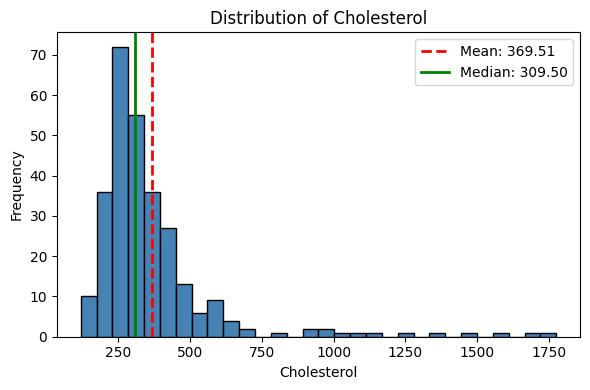

In [35]:
plot_numeric_histogram(cirrhosis_data, 'Cholesterol')

Można założyć, że jest to rozkład asymetryczny prawoskośny, ponieważ:
* większość wartości skupia się po lewej stronie (około 200–400),
* po prawej stronie jest długi „ogon” aż do bardzo dużych wartości (~1800),
* średnia jest większa od mediany(ponieważ kilka bardzo dużych wartości cholesterolu ciągnie średnią w prawo)

Zatem brakujące wartości w kolumnie Cholesterol uzupełnię medianą. Przy skośnym/ asymetrycznym rozkładzie danych jest to bezpieczniejsze, użycie średniej mogłoby zawyżyć wiele brakujących wartości.


In [36]:
cirrhosis_data['Cholesterol'] = cirrhosis_data['Cholesterol'].fillna(cirrhosis_data['Cholesterol'].median())
cirrhosis_data['Cholesterol'].isna().sum()

np.int64(0)

### Copper

Dla zmiennej Copper również zbadam jej rozkład przed uzupełnieniem braków

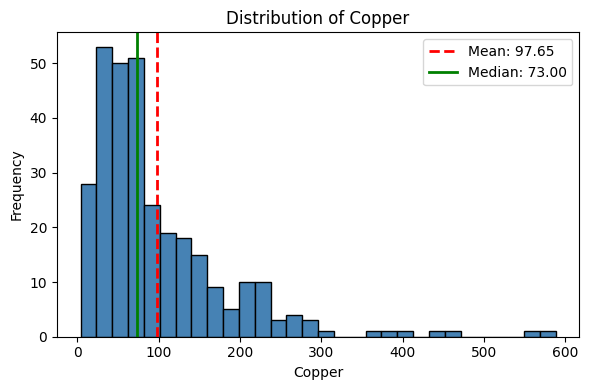

In [37]:
plot_numeric_histogram(cirrhosis_data, 'Copper')

Ponownie dane mają rozkład asymetryczny prawoskośny, dlatego ponownie brakujące wartości wypełnią medianą.

In [38]:
cirrhosis_data['Copper'] = cirrhosis_data['Copper'].fillna(cirrhosis_data['Copper'].median())
cirrhosis_data['Copper'].isna().sum()

np.int64(0)

### Alk_Phos

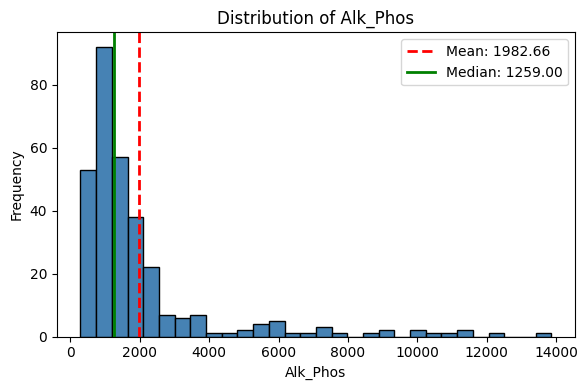

In [39]:
plot_numeric_histogram(cirrhosis_data, 'Alk_Phos')

Również można założyć, że mamy tutaj do czynienia z rozkładem asymetrycznie prawoskośnym, więc dane ponownie uzupełnie medianą.

In [40]:
cirrhosis_data['Alk_Phos'] = cirrhosis_data['Alk_Phos'].fillna(cirrhosis_data['Alk_Phos'].median())
cirrhosis_data['Alk_Phos'].isna().sum()

np.int64(0)

### SGOT

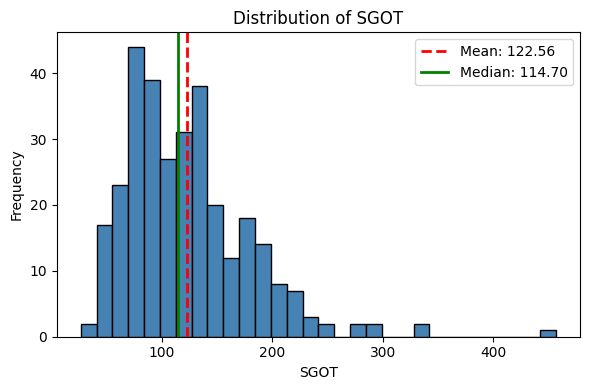

In [41]:
plot_numeric_histogram(cirrhosis_data, 'SGOT')

Rozkład dla cechy SGOT jest już bliski rozkładowi normalnemu, jednak wciąż jest lekko prawoskośny. Różnica między medianą oraz średnią jest niewielka, dlatego w tym przypadku zdecydowałam się zastapić wartości NULL średnią.

In [42]:
cirrhosis_data['SGOT'] = cirrhosis_data['SGOT'].fillna(cirrhosis_data['SGOT'].mean())
cirrhosis_data['SGOT'].isna().sum()

np.int64(0)

### Tryglicerides

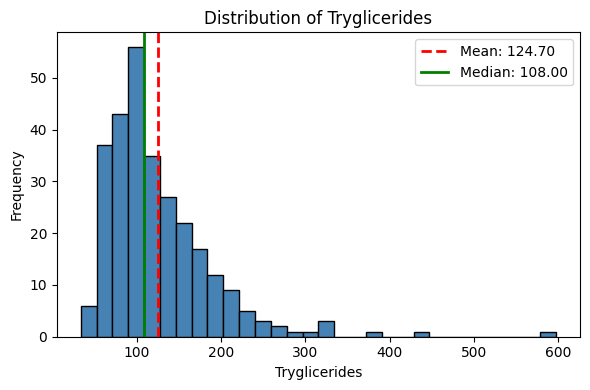

In [43]:
plot_numeric_histogram(cirrhosis_data, 'Tryglicerides')

Ponownie dane mają rozkład asymetryczny prawoskośny, dlatego ponownie brakujące wartości wypełnią medianą.

In [44]:
cirrhosis_data['Tryglicerides'] = cirrhosis_data['Tryglicerides'].fillna(cirrhosis_data['Tryglicerides'].median())
cirrhosis_data['Tryglicerides'].isna().sum()

np.int64(0)

### Platelets

W kolumnie Platelets brakuje tylko 4 wartości. Sprawdzę rozkład i uzupełnię medianą lub średnią.

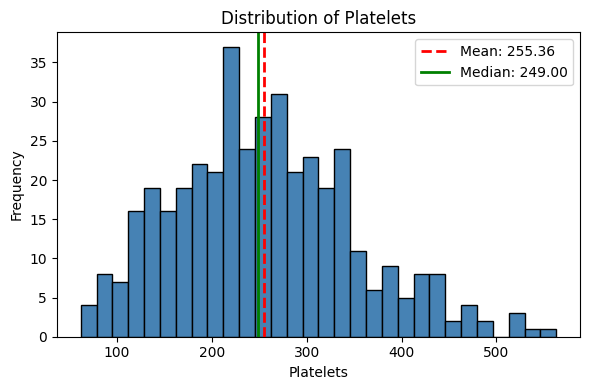

In [45]:
plot_numeric_histogram(cirrhosis_data, 'Platelets')

Rozkład dla cechy Plateles jest można uznać za rozkład normalny. Różnica między medianą oraz średnią jest minimalna. W tym przypadku najlepszym rowiązaniem jest uzupełnienie wartości NULL średnią.

In [46]:
cirrhosis_data['Platelets'] = cirrhosis_data['Platelets'].fillna(cirrhosis_data['Platelets'].mean())
cirrhosis_data['Platelets'].isna().sum()

np.int64(0)

## Kolumny kategorialne

Definiuję funkcję pomocniczą do pobierania rozkładu wartości kolumny

In [47]:
def get_column_distribution(df, column):
    return df[column].value_counts(normalize=True)

### Drug

Kolumna Drug jest kategorialna z 2 możliwymi wartościami. Sprawdzę rozkład danych.

In [48]:
cirrhosis_data['Drug'].isna().sum()

np.int64(91)

In [49]:
cirrhosis_data['Drug'].unique()

<StringArray>
['D-penicillamine', 'Placebo', nan]
Length: 3, dtype: str

In [ ]:
drug_dist = get_column_distribution(cirrhosis_data, 'Drug')
drug_dist

Drug
D-penicillamine    0.50641
Placebo            0.49359
Name: proportion, dtype: float64

Rozkład wartości Drug jest zbliżony (około 50% wierszy ma wartość D-penicillamine i około 50% wierszy ma wartość Placebo). Brakujące wartości można uzupełnić:
1) wartością najczęścięj występującą w kolumnie (tutaj bez sensu)
2) zgodnie z rozkładem istniejących danych, losowo uzupełniająć wartości brakujące
3) dodając nową wartość Drug = "Unknown" dla wierszy z NULLami

Jako iż mamy 91 brakujących wartości losowe uzupełnienie według rozkładu danych mogłoby wpłynąć na skuteczność modelu, dlatego zdecydowałam się użyć podejścia nr 3. 

In [53]:
cirrhosis_data['Drug'] = cirrhosis_data['Drug'].fillna("Unknown")

In [54]:
cirrhosis_data['Drug'].isna().sum()

np.int64(0)

In [55]:
cirrhosis_data['Drug'].unique()

<StringArray>
['D-penicillamine', 'Placebo', 'Unknown']
Length: 3, dtype: str

### Ascites

Kolumna Ascites jest binarna (Y/N). Sprawdzę rozkład danych.

In [56]:
ascites_dist = get_column_distribution(cirrhosis_data, 'Ascites')
ascites_dist

Ascites
N    288
Y     24
Name: count, dtype: int64

Brakujące dane zdecydowałam się uzupełnić losowo według rozkładu danych. Mimo, że większośc danych w kolumnie Ascites ma wartość 'N', to uzupełnienie wszystkich 91 wierszy z wartością NaN za pomocą 'N' mogłoby negatywnie wpłynąć na skuteczność modelu.

In [58]:
ascites_dist = get_column_distribution(cirrhosis_data, 'Ascites')
ascites_values = ascites_dist.index
ascites_probs = ascites_dist.values
missing_ascites = cirrhosis_data['Ascites'].isna()
cirrhosis_data.loc[missing_ascites, 'Ascites'] = np.random.choice(ascites_values, size=missing_ascites.sum(), p=ascites_probs)
cirrhosis_data['Ascites'].isna().sum()

np.int64(0)

### Hepatomegaly

Kolumna Hepatomegaly jest binarna (Y/N). Sprawdzę rozkład danych.

In [59]:
cirrhosis_data['Hepatomegaly'].value_counts()

Hepatomegaly
Y    160
N    152
Name: count, dtype: int64

Tutaj tak jak w przypadku kolumny Drug mamy prawie rozkład 50/50 pomiędzy wartościami 'Y' oraz 'N'. DLatego zdecydowałam się dodać wartość "Unknown" i nią uzupełnić wartości brakujące.

In [60]:
cirrhosis_data['Hepatomegaly'] = cirrhosis_data['Hepatomegaly'].fillna("Unknown")
cirrhosis_data['Hepatomegaly'].isna().sum()

np.int64(0)

In [61]:
cirrhosis_data['Hepatomegaly'].unique()

<StringArray>
['Y', 'N', 'Unknown']
Length: 3, dtype: str

### Spiders

Kolumna Spiders jest binarna (Y/N). Sprawdzę rozkład danych.

In [62]:
cirrhosis_data['Spiders'].value_counts()

Spiders
N    222
Y     90
Name: count, dtype: int64

Brakujące dane zdecydowałam się uzupełnić losowo według rozkładu danych. 

In [65]:
spiders_dist = get_column_distribution(cirrhosis_data, 'Spiders')
spiders_values = spiders_dist.index
spiders_probs = spiders_dist.values
missing_spiders = cirrhosis_data['Spiders'].isna()
cirrhosis_data.loc[missing_spiders, 'Spiders'] = np.random.choice(spiders_values, size=missing_spiders.sum(), p=spiders_probs)
cirrhosis_data['Spiders'].isna().sum()

np.int64(0)

## Weryfikacja – brak wartości NaN

In [66]:
cirrhosis_data.isna().sum()

N_Days           0
Status           0
Drug             0
Age              0
Sex              0
Ascites          0
Hepatomegaly     0
Spiders          0
Edema            0
Bilirubin        0
Cholesterol      0
Albumin          0
Copper           0
Alk_Phos         0
SGOT             0
Tryglicerides    0
Platelets        0
Prothrombin      0
Stage            0
dtype: int64

# **Wykrywanie outlierów**

Definiuję funkcję pomocniczą do rysowania wykresu pudełkowego (boxplot)

In [67]:
def boxplot(df, column_name):
    plt.figure(figsize=(10, 4))
    sns.boxplot(x=df[column_name].dropna(), color='lightgreen')
    plt.title(f'Distribution of {column_name} (boxplot)')
    plt.xlabel(column_name)
    plt.show()

Definiuję funkcję pomocniczą do rysowania scatter plot

In [68]:
def scatterplot(df, column_name, y):
    plt.figure(figsize=(6, 4))
    sns.scatterplot(data=df, x=column_name, y=y, color='darkorange', alpha=0.6)
    plt.title(f'{column_name} vs {y}')
    plt.xlabel(column_name)
    plt.ylabel(y)
    plt.tight_layout()
    plt.show()

### Bilirubin

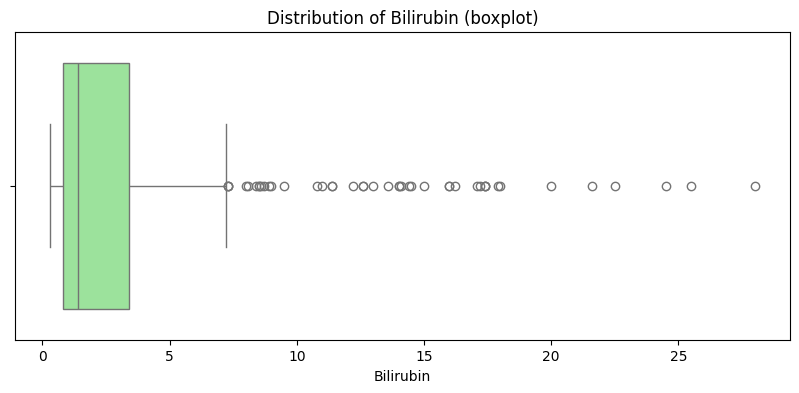

In [69]:
boxplot(cirrhosis_data, 'Bilirubin')

Można zauważyć, że w kolumnie Bilirubin jest sporo outlierów. Możemy albo usunąć wartości odstające albo pozostawić je, ponieważ mogą mieć duża wartość dla modelu, być mocno powiązane z wartością w kolumnie Status.

Dlatego sprawdzę czy nie ma korelacji pomiędzy wysokim Bilirubin, a statusem pacjenta.

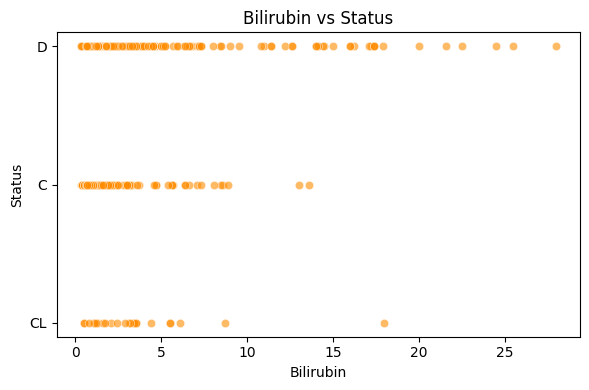

In [71]:
scatterplot(cirrhosis_data, 'Bilirubin', 'Status')

Jak widać dla wysokich wartości w kolumnie Bilirubin w większości status ma wartosć 'D'. Dlatego zdecydowałam się nie usuwać outlierów.

### Cholesterol

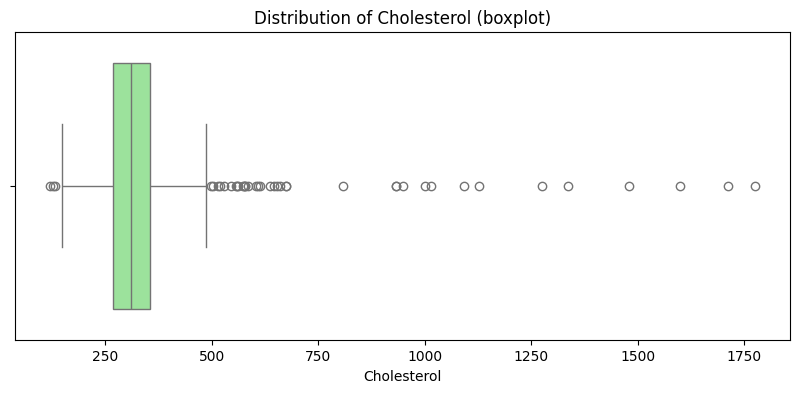

In [72]:
boxplot(cirrhosis_data, 'Cholesterol')

Dla kolumny Cholesterol również występuję wiele wartości odstających.
Również sprawdzę czy nie ma korelacji pomiędzy wysokim Cholesterolem, a statusem pacjenta.

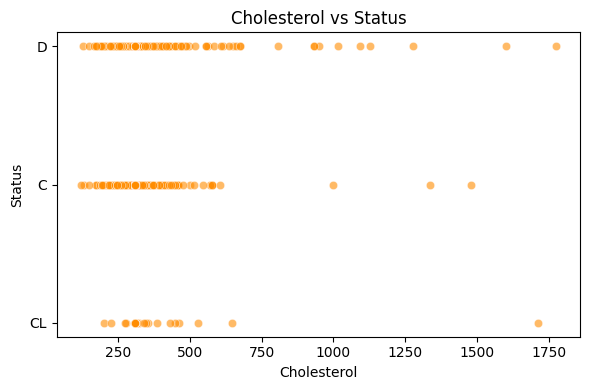

In [74]:
scatterplot(cirrhosis_data, 'Cholesterol', 'Status')

Dla odstających wartości w kolumnie Cholesterol , Status ma zarówno wartość 'D', 'C', 'CL', z dominującą wartością 'D', dlatego mimo wszytsko zdecydowałam się pozostawić te outliery.

### Copper

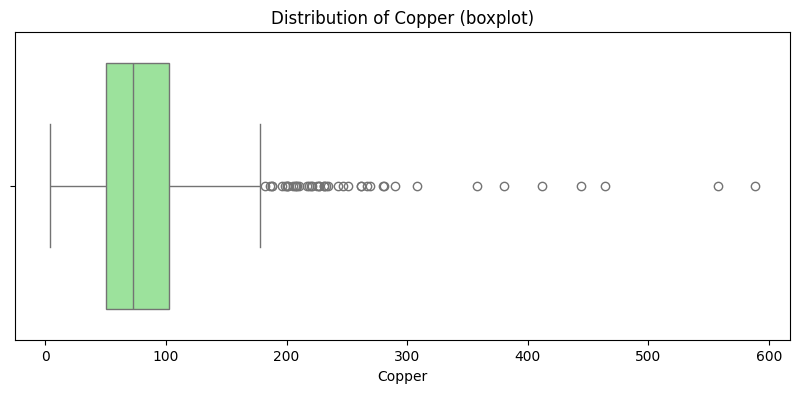

In [75]:
boxplot(cirrhosis_data, 'Copper')

Sprawdzę czy wysokie wartości Copper korelują z długością przeżycia pacjenta

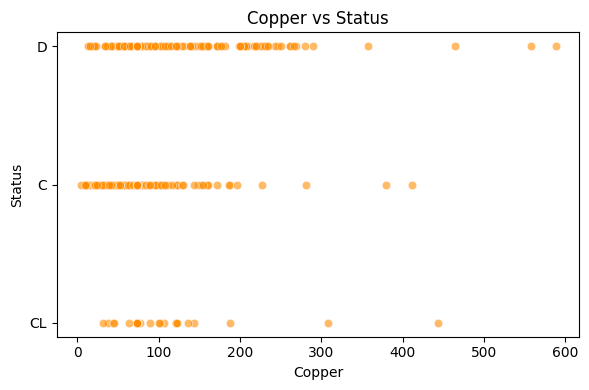

In [77]:
scatterplot(cirrhosis_data, 'Copper', 'Status')

Dla odstających wartości w kolumnie Copper , Status ma zarówno wartość 'D', 'C', 'CL'. Zdecydowałam się pozostawić te outliery.

### Alk_Phos

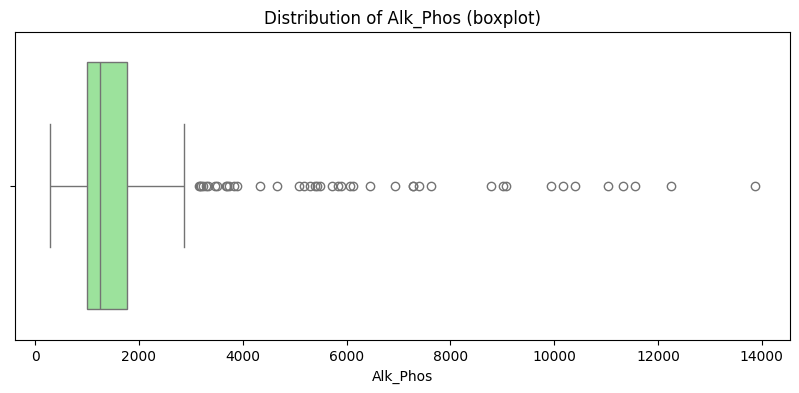

In [79]:
boxplot(cirrhosis_data, 'Alk_Phos')

Sprawdzę czy wysokie wartości Alk_Phos korelują z długością przeżycia pacjenta

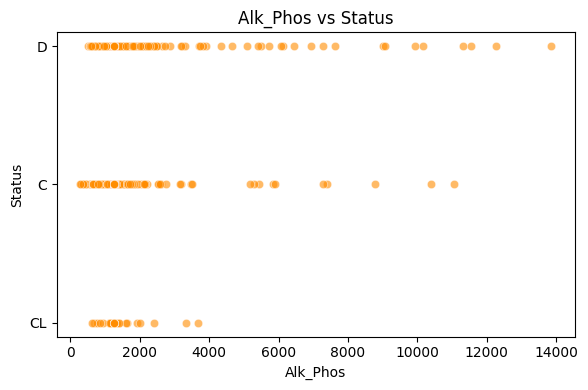

In [80]:
scatterplot(cirrhosis_data, 'Alk_Phos', 'Status')

Dla odstających wartości w kolumnie Alk_Phos , Status ma zarówno wartość 'D', 'C', 'CL'. Zdecydowałam się pozostawić te outliery.

### SGOT

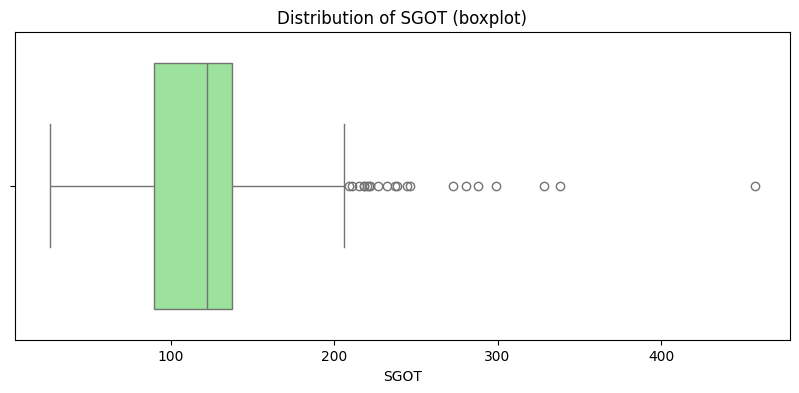

In [81]:
boxplot(cirrhosis_data, 'SGOT')

Sprawdzę czy wysokie wartości SGOT nkorelują z długością przeżycia pacjenta

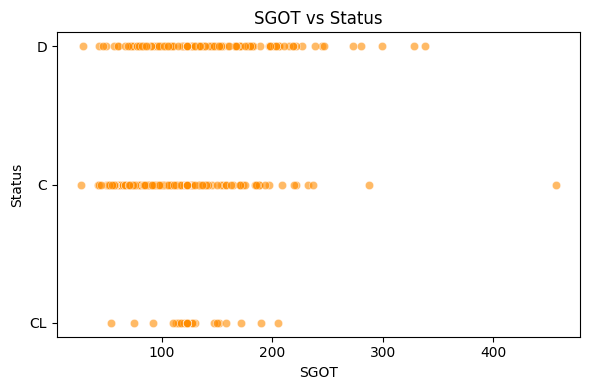

In [82]:
scatterplot(cirrhosis_data, 'SGOT', 'Status')

Dla odstających wartości w kolumnie SGOT , Status ma zarówno wartość 'D', 'C', 'CL'. Zdecydowałam się pozostawić te outliery.

### Tryglicerides

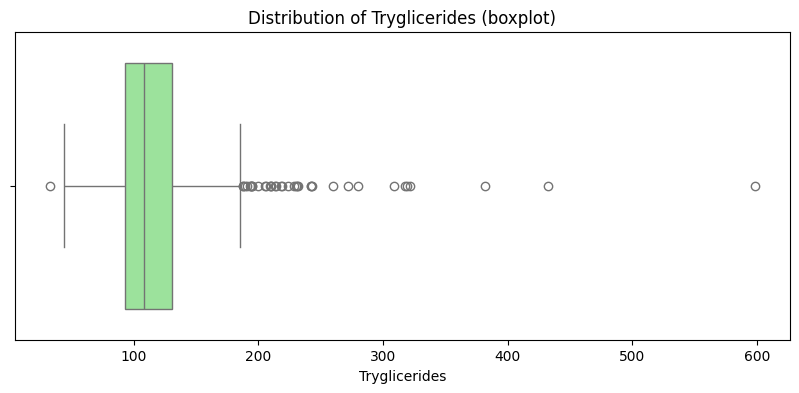

In [83]:
boxplot(cirrhosis_data, 'Tryglicerides')

Sprawdzę czy wysokie wartości Tryglicerides nkorelują z długością przeżycia pacjenta

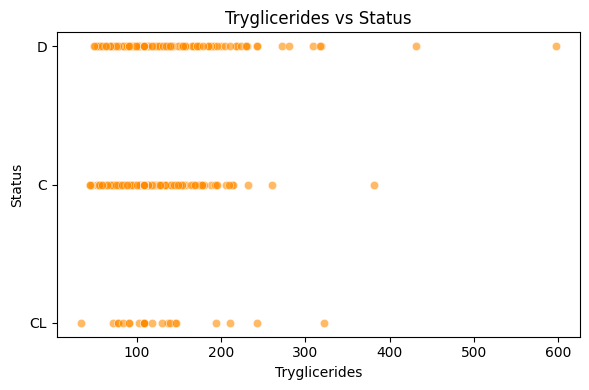

In [87]:
scatterplot(cirrhosis_data, 'Tryglicerides', 'Status')

### Platelets

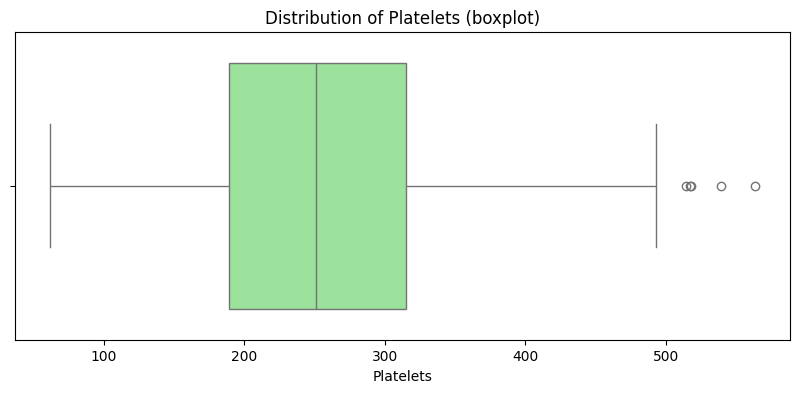

In [84]:
boxplot(cirrhosis_data, 'Platelets')

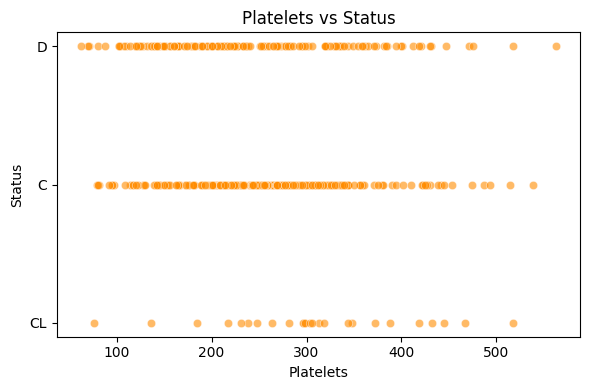

In [85]:
scatterplot(cirrhosis_data, 'Platelets', 'Status')

### Prothrombin

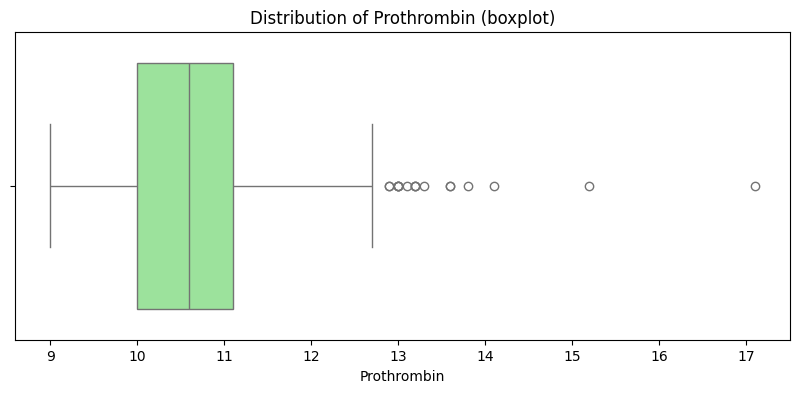

In [88]:
boxplot(cirrhosis_data, 'Prothrombin')

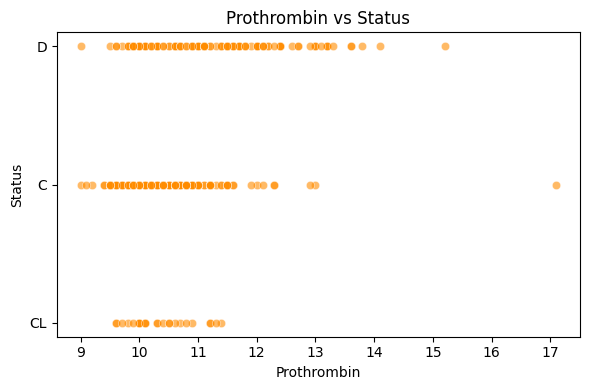

In [89]:
scatterplot(cirrhosis_data, 'Prothrombin', 'Status')

Dla wszystkich 3 kolumn : Tryglicerides, Plateles, Prothrombrin zdecydowałam się pozostawić te outliery.

#### Dla kolumn kategorialnych binarnych (Drug, Ascites, Hepatomegaly, Spiders, Sex, Edema) oraz dla Stage nie ma potrzeby badania outlierów – każda z nich ma wartości z ściśle określonego, skończonego zbioru.

# **Wizualizacje danych**

Sprawdzę rozkład statusów pacjentów – zmiennej docelowej

C:\Users\mazur\AppData\Local\Temp\ipykernel_38588\803747020.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Status', data=cirrhosis_data, palette='viridis')


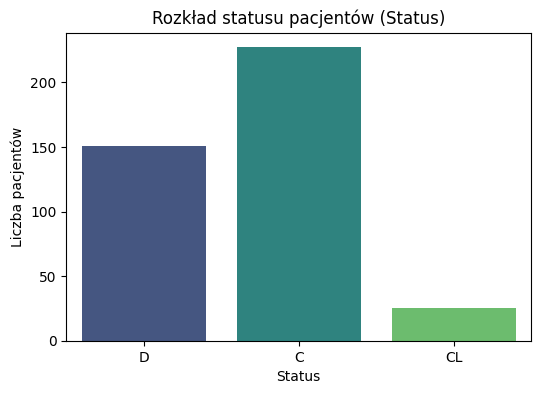

In [90]:
plt.figure(figsize=(6, 4))
sns.countplot(x='Status', data=cirrhosis_data, palette='viridis')
plt.title('Rozkład statusu pacjentów (Status)')
plt.xlabel('Status')
plt.ylabel('Liczba pacjentów')
plt.show()

Mamy ponad 200 pacjentów ze statusem 'C' oraz 150 pacjentów ze statusem 'D'. Najrzadziej występującą wartościa jest 'CL'. Można się spodziewać, że klasyfikacja tego statusu może być najtrudniejsza.

Sprawdzę rozkład stadium choroby (Stage) w zależności od statusu pacjenta za pomocą heatmapy

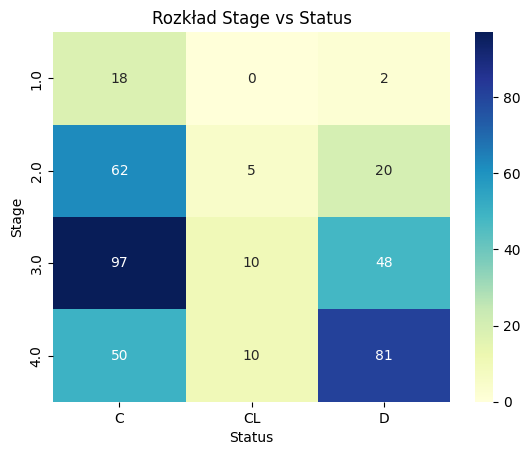

In [91]:
cross_tab = pd.crosstab(cirrhosis_data['Stage'], cirrhosis_data['Status'])
sns.heatmap(cross_tab, annot=True, fmt='d', cmap='YlGnBu')
plt.title('Rozkład Stage vs Status')
plt.show()

Można uznać, że dla Stage 3.0 oraz 4,0 zarówno wartości 'C' oraz 'CL' jak i 'D' występują częsciej, co zonacza, że nie można uznać, że wysoki Stage przyczynia się do większej śmiertelności pacjenta. Może to również oznaczać, że po prostu większość badanych pacjentów miała Stahe 3/4.

Sprawdzę jak rozkłada się płeć wśród pacjentów.

C:\Users\mazur\AppData\Local\Temp\ipykernel_38588\663230330.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Sex', data=cirrhosis_data, palette='viridis')


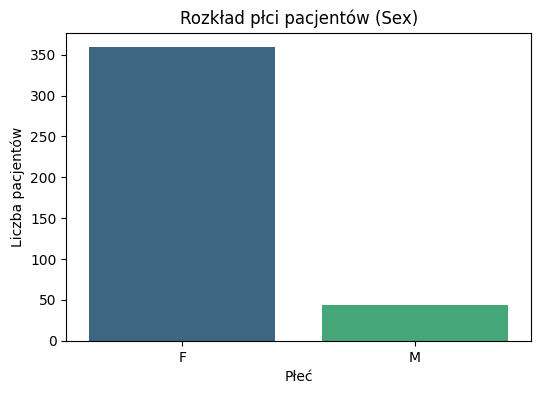

In [94]:
plt.figure(figsize=(6, 4))
sns.countplot(x='Sex', data=cirrhosis_data, palette='viridis')
plt.title('Rozkład płci pacjentów (Sex)')
plt.xlabel('Płeć')
plt.ylabel('Liczba pacjentów')
plt.show()

Sprawdzę czy płeć pacjenta ma związek ze statusem (przeżywalnością)

C:\Users\mazur\AppData\Local\Temp\ipykernel_38588\2559971816.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=category_col, y='Odsetek zgonów', data=death_rate, palette='coolwarm')


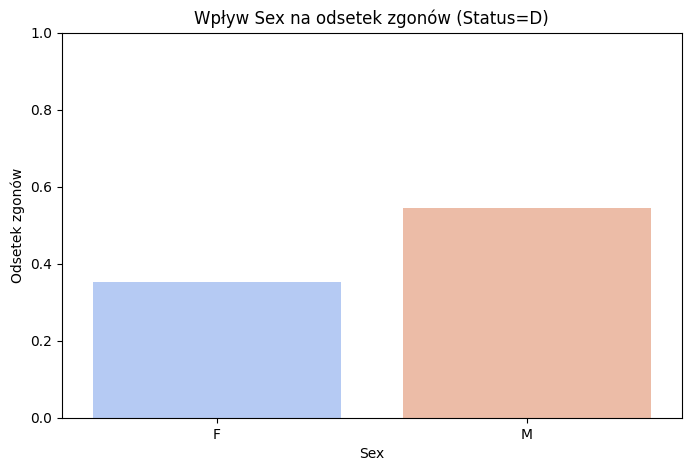

In [92]:
def plot_status_barplot(df, category_col):
    death_rate = df[df['Status'] == 'D'].groupby(category_col).size() / df.groupby(category_col).size()
    death_rate = death_rate.reset_index(name='Odsetek zgonów')

    plt.figure(figsize=(8, 5))
    sns.barplot(x=category_col, y='Odsetek zgonów', data=death_rate, palette='coolwarm')
    plt.title(f'Wpływ {category_col} na odsetek zgonów (Status=D)')
    plt.xlabel(category_col)
    plt.ylabel('Odsetek zgonów')
    plt.ylim(0, 1)
    plt.show()

plot_status_barplot(cirrhosis_data, 'Sex')

Większa śmiertelność występuję wśród mężczyzn, jednak większość pacjentek to kobiety, dlatego ciężko określić czy śmiertelność koreluje z płcią, czy tez dla kobiet odsetek zgonów jest niższy przez większą liczbę rekordów.

Sprawdzę wpływ obecności objawów klinicznych (Ascites, Hepatomegaly, Spiders, Edema) na odsetek zgonów

C:\Users\mazur\AppData\Local\Temp\ipykernel_38588\2559971816.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=category_col, y='Odsetek zgonów', data=death_rate, palette='coolwarm')


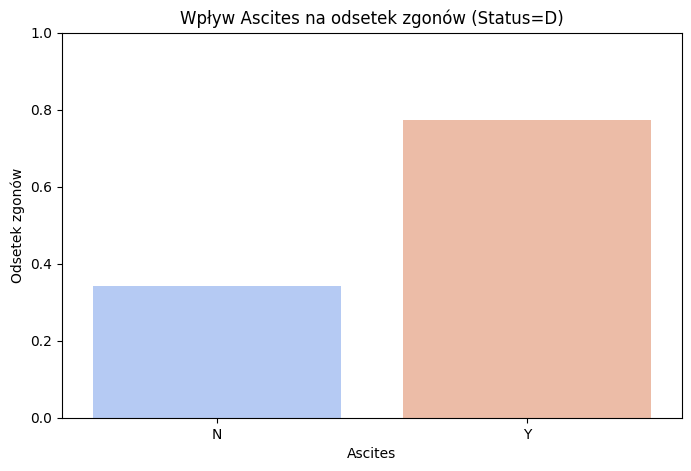

C:\Users\mazur\AppData\Local\Temp\ipykernel_38588\2559971816.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=category_col, y='Odsetek zgonów', data=death_rate, palette='coolwarm')


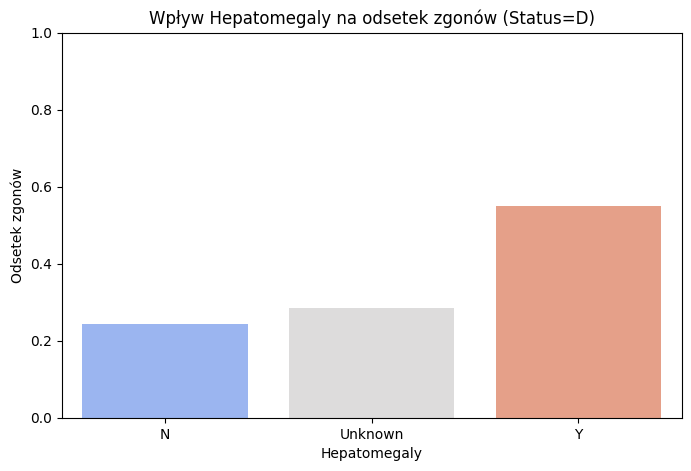

C:\Users\mazur\AppData\Local\Temp\ipykernel_38588\2559971816.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=category_col, y='Odsetek zgonów', data=death_rate, palette='coolwarm')


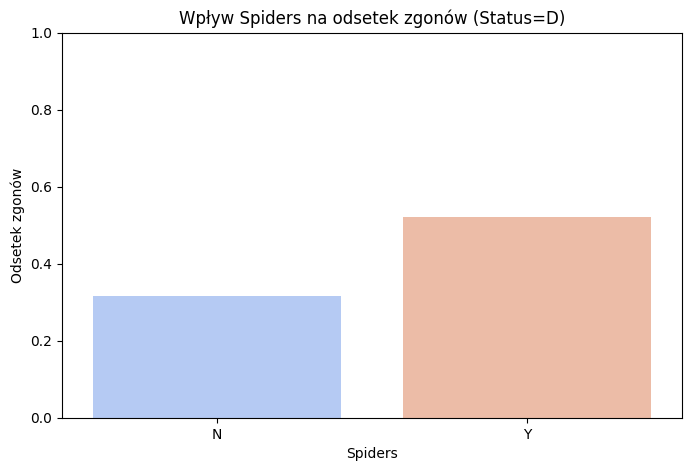

C:\Users\mazur\AppData\Local\Temp\ipykernel_38588\2559971816.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=category_col, y='Odsetek zgonów', data=death_rate, palette='coolwarm')


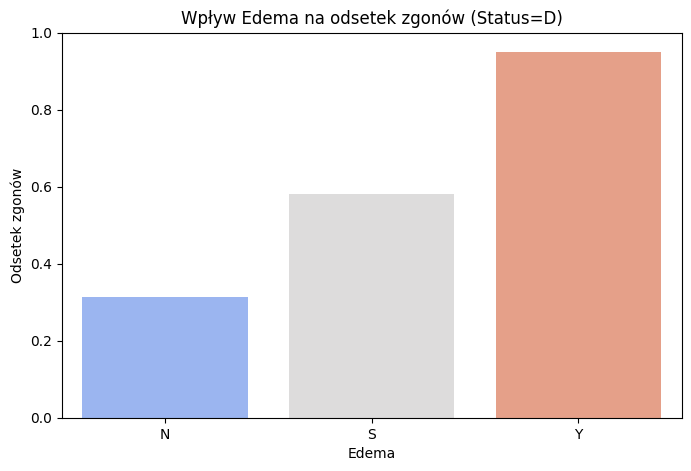

In [95]:
plot_status_barplot(cirrhosis_data, 'Ascites')
plot_status_barplot(cirrhosis_data, 'Hepatomegaly')
plot_status_barplot(cirrhosis_data, 'Spiders')
plot_status_barplot(cirrhosis_data, 'Edema')

Dla wszystkich 4 cech widzimy, że obecnośc objawów klinicznych koreluje z wyższym odsetkiem zgonów, więc mogą to być to kluczowe cechy dla modelu.

Sprawdzę czy podawany lek (Drug) miał wpływ na wynik leczenia

C:\Users\mazur\AppData\Local\Temp\ipykernel_38588\2559971816.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=category_col, y='Odsetek zgonów', data=death_rate, palette='coolwarm')


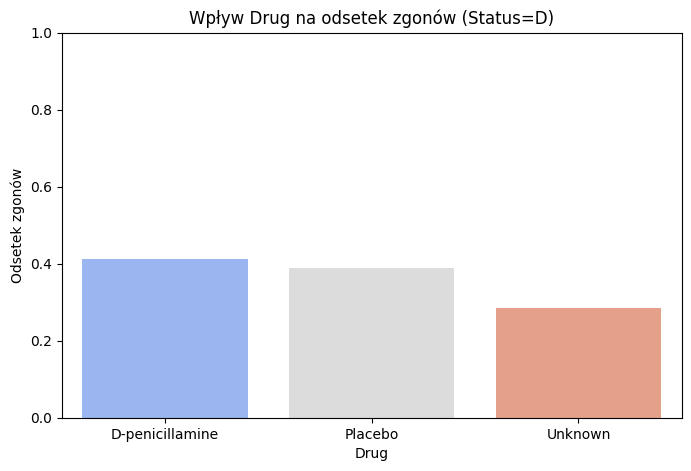

In [96]:
plot_status_barplot(cirrhosis_data, 'Drug')

Podawany lek nie wykazuje silnej zależności z Statusem pacjentów, dla wszystkich 3 wartości w kolumnie Drug odetek zgonów jest na podobnym poziomie, możemy zatem uznać, że nie będzie to kluczowa cecha dla naszego modelu.

Sprawdzę zależność Bilirubin i Albumin od stadium choroby za pomocą pivot table i heatmapy

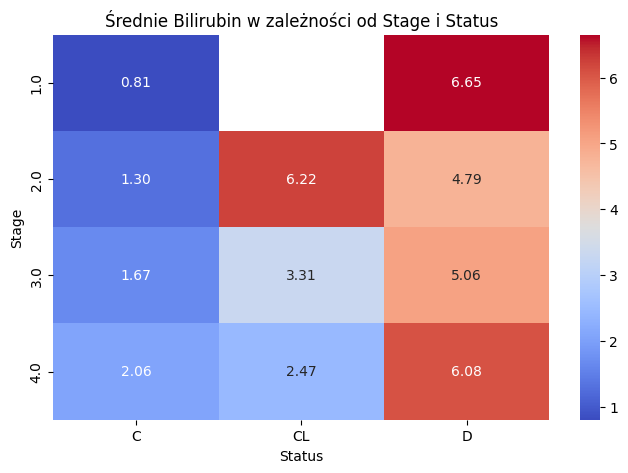

In [97]:
pivot_bilirubin = cirrhosis_data.pivot_table(index='Stage', columns='Status', values='Bilirubin', aggfunc='mean')

plt.figure(figsize=(8, 5))
sns.heatmap(pivot_bilirubin, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Średnie Bilirubin w zależności od Stage i Status')
plt.ylabel('Stage')
plt.xlabel('Status')
plt.show()

Widać, że dla Statusu 'D' średnie Bilirubin jest wyższe, więc może ono mieć wpływ na śmiertelność pacjenta.

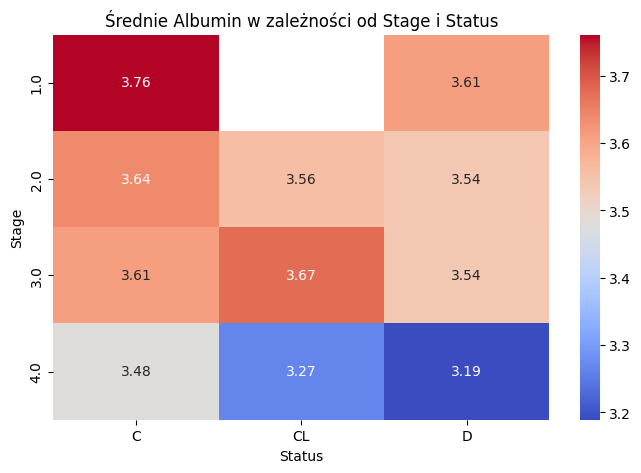

In [98]:
pivot_albumin = cirrhosis_data.pivot_table(index='Stage', columns='Status', values='Albumin', aggfunc='mean')

plt.figure(figsize=(8, 5))
sns.heatmap(pivot_albumin, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Średnie Albumin w zależności od Stage i Status')
plt.ylabel('Stage')
plt.xlabel('Status')
plt.show()

Nie widać większej zależności pomiędzy cechą Status i Stage, a średnią Albumin. Większość wartości na heatmapie są do siebie zbliżone.